# Analyzing the Impact of Economic Recession on Automobile Sales

**IBM / Coursera — Final Assignment Part 1: Matplotlib, Seaborn & Folium**

This independently reconstructed notebook follows the nine tasks described in the course assignment. It uses the **official IBM Skills Network data**; results are not simulated. The course starter notebook was not supplied, so this is not represented as an edited original.

## Data source and setup

Download the original dataset once with `python scripts/fetch_dataset.py` from the repository root. The notebook refuses to substitute synthetic data. Set the working directory to the repository root or the notebook directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import sys

sns.set_theme(style="whitegrid")
DATA_PATH = next((p for p in [Path("../data/historical_automobile_sales.csv"), Path("data/historical_automobile_sales.csv")] if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Official IBM dataset missing. Run `python scripts/fetch_dataset.py` from repository root.")
sys.path.insert(0, str(DATA_PATH.resolve().parents[1] / "scripts"))
from check_dataset import parse_months
df = pd.read_csv(DATA_PATH)
required = {"Year", "Month", "Automobile_Sales", "Vehicle_Type", "Recession", "GDP", "Price", "Seasonality_Weight", "Advertising_Expenditure", "unemployment_rate"}
assert required <= set(df), f"Missing columns: {sorted(required - set(df))}"
# Numeric parsing is explicit: reject malformed values rather than comparing text to numbers.
for _numeric_column in ['Year', 'Recession', 'Automobile_Sales', 'GDP', 'Price', 'Seasonality_Weight', 'Advertising_Expenditure', 'unemployment_rate']:
    df[_numeric_column] = pd.to_numeric(df[_numeric_column], errors='raise')
df["Month_Number"] = parse_months(df["Month"])
assert df["Recession"].isin([0,1]).all()
df.head()

,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City,Month_Number
0,1/31/1980,1980,Jan,1,108.24,0.50,27483.571,1558,7,60.223,0.010000,5.4,456.0,Supperminicar,Georgia,1
1,2/29/1980,1980,Feb,1,98.75,0.75,24308.678,3048,4,45.986,-0.309594,4.8,555.9,Supperminicar,New York,2
2,3/31/1980,1980,Mar,1,107.48,0.20,28238.443,3137,3,35.141,-0.308614,3.4,620.0,Mediumfamilycar,New York,3
3,4/30/1980,1980,Apr,1,115.01,1.00,32615.149,1653,7,45.673,0.230596,4.2,702.8,Supperminicar,Illinois,4
4,5/31/1980,1980,May,1,98.72,0.20,23829.233,1319,4,52.997,0.138197,5.3,770.4,Smallfamiliycar,California,5


### Dataset quality checks

Report row count, date range, recession classes and missing values before interpreting charts.

In [2]:
print(f"Rows: {len(df):,}; years: {df['Year'].min()}–{df['Year'].max()}")
print("Recession flags:", df['Recession'].value_counts().to_dict())
print("Nulls:", df.isna().sum().to_dict())

Rows: 528; years: 1980–2023
Recession flags: {0: 415, 1: 113}
Nulls: {'Date': 0, 'Year': 0, 'Month': 0, 'Recession': 0, 'Consumer_Confidence': 0, 'Seasonality_Weight': 0, 'Price': 0, 'Advertising_Expenditure': 0, 'Competition': 0, 'GDP': 0, 'Growth_Rate': 0, 'unemployment_rate': 0, 'Automobile_Sales': 0, 'Vehicle_Type': 0, 'City': 0, 'Month_Number': 0}


## Task 1.1 — Yearly automobile sales over time

A yearly mean is used to compare performance across years with consistent monthly granularity.

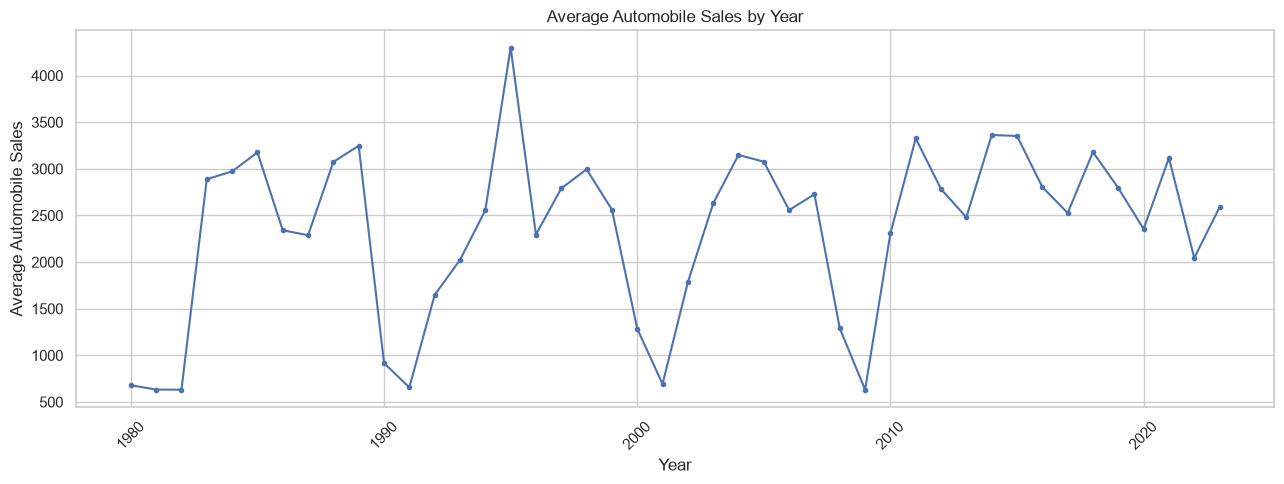

Interpretation (observed data): highest yearly mean is 1995 (4,300.25); lowest is 1982 (631.15).


In [3]:
annual = df.groupby('Year', as_index=False)['Automobile_Sales'].mean()
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(annual['Year'], annual['Automobile_Sales'], marker='o', markersize=3)
ax.set(title='Average Automobile Sales by Year', xlabel='Year', ylabel='Average Automobile Sales')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print(f"Interpretation (observed data): highest yearly mean is {annual.loc[annual.Automobile_Sales.idxmax(), 'Year']} ({annual.Automobile_Sales.max():,.2f}); lowest is {annual.loc[annual.Automobile_Sales.idxmin(), 'Year']} ({annual.Automobile_Sales.min():,.2f}).")


## Task 1.2 — Advertising expenditure and sales in non-recession periods

Two separate scales avoid implying that advertising spending and sales have identical units.

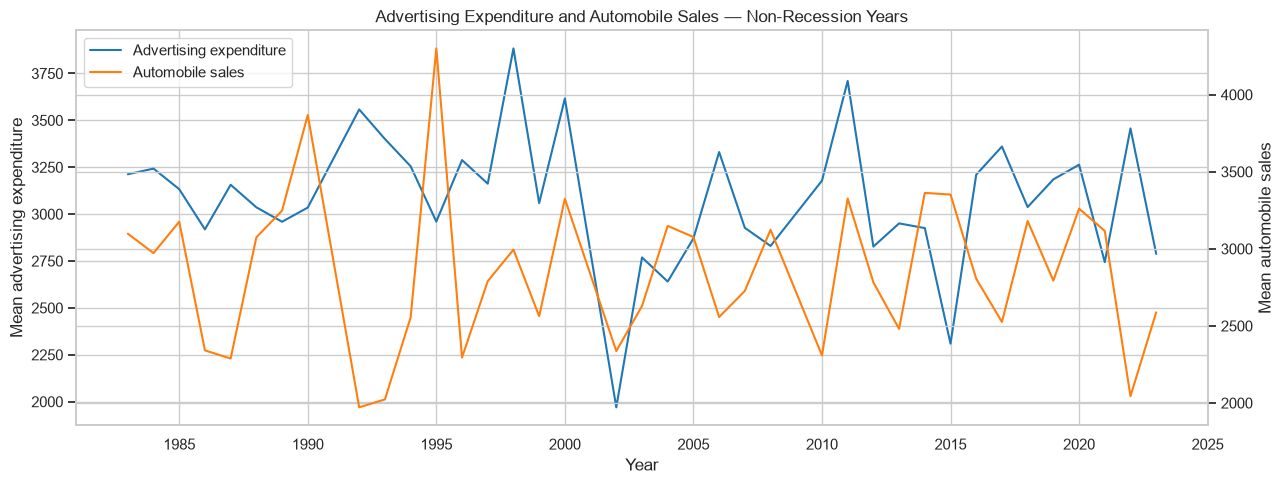

Interpretation (non-recession yearly means): advertising/sales Pearson correlation = -0.124


In [4]:
non_rec = df.loc[df['Recession'] == 0]
non_rec_yearly = non_rec.groupby('Year', as_index=False)[['Advertising_Expenditure','Automobile_Sales']].mean()
fig, ax1 = plt.subplots(figsize=(13,5))
line1 = ax1.plot(non_rec_yearly['Year'], non_rec_yearly['Advertising_Expenditure'], color='tab:blue', label='Advertising expenditure')
ax2 = ax1.twinx()
line2 = ax2.plot(non_rec_yearly['Year'], non_rec_yearly['Automobile_Sales'], color='tab:orange', label='Automobile sales')
ax1.set(xlabel='Year', ylabel='Mean advertising expenditure', title='Advertising Expenditure and Automobile Sales — Non-Recession Years')
ax2.set_ylabel('Mean automobile sales')
ax1.legend(line1+line2, [l.get_label() for l in line1+line2], loc='upper left')
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (non-recession yearly means): advertising/sales Pearson correlation =', round(non_rec_yearly['Advertising_Expenditure'].corr(non_rec_yearly['Automobile_Sales']), 3))


### Additional IBM rubric check for Task 1.2 — Recession sales trends by vehicle type

The original IBM course rubric describes Task 1.2 as comparing **vehicle-type sales trends during recessions**, whereas the supplied custom brief requests non-recession advertising expenditure versus sales. Both analyses are preserved for compatibility; neither replaces the other.


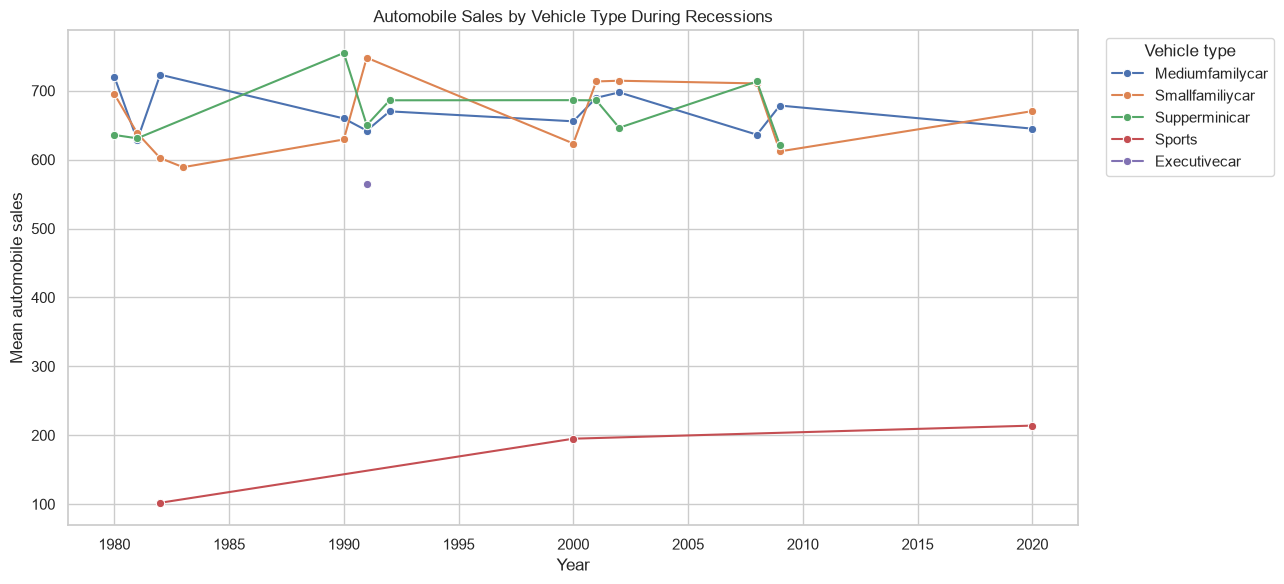

Interpretation (recession mean sales by type):
Vehicle_Type
Supperminicar      671.10
Mediumfamilycar    670.56
Smallfamiliycar    662.19
Executivecar       564.00
Sports             170.33


In [5]:
recession_by_type = (df.loc[df['Recession'] == 1]
    .groupby(['Year', 'Vehicle_Type'], as_index=False)['Automobile_Sales'].mean())
fig, ax = plt.subplots(figsize=(13, 6))
sns.lineplot(data=recession_by_type, x='Year', y='Automobile_Sales', hue='Vehicle_Type', marker='o', ax=ax)
ax.set(title='Automobile Sales by Vehicle Type During Recessions', xlabel='Year', ylabel='Mean automobile sales')
ax.legend(title='Vehicle type', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()

# Computed only when executed on the official IBM dataset.
print('Interpretation (recession mean sales by type):')
print(recession_by_type.groupby('Vehicle_Type')['Automobile_Sales'].mean().sort_values(ascending=False).round(2).to_string())


## Task 1.3 — Grouped vehicle-type bar chart

Exact Seaborn syntax required by the assignment. Bars show mean sales, not total sales.

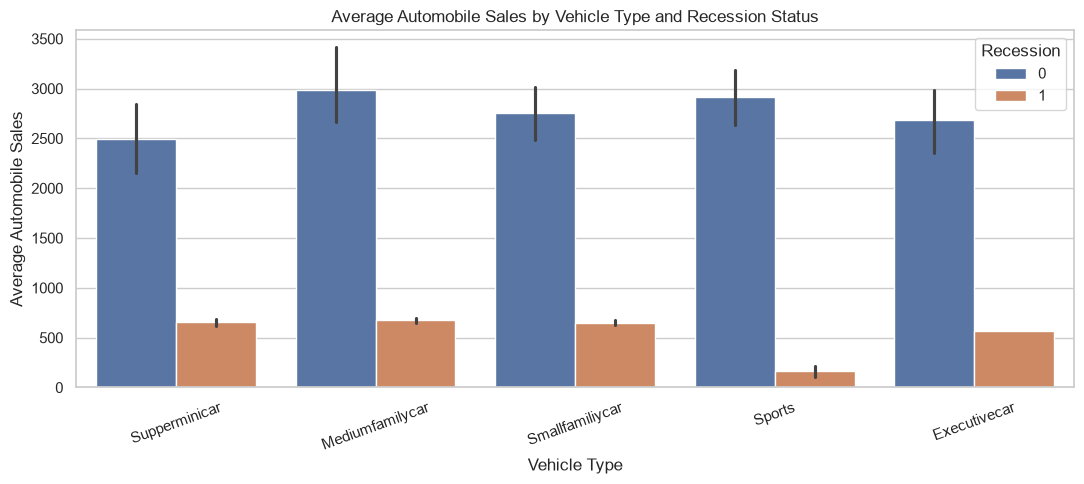

Interpretation (original data, average sales per vehicle type and regime):
Recession              0       1
Vehicle_Type                    
Executivecar     2686.44  564.00
Mediumfamilycar  2981.50  674.85
Smallfamiliycar  2752.66  650.73
Sports           2910.64  170.33
Supperminicar    2495.24  659.27


In [6]:
fig, ax = plt.subplots(figsize=(11,5))
sns.barplot(x='Vehicle_Type', y='Automobile_Sales', hue='Recession', data=df, ax=ax)
ax.set(title='Average Automobile Sales by Vehicle Type and Recession Status', xlabel='Vehicle Type', ylabel='Average Automobile Sales')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (original data, average sales per vehicle type and regime):')
print(df.groupby(['Vehicle_Type', 'Recession'])['Automobile_Sales'].mean().unstack().round(2).to_string())


## Task 1.4 — GDP subplots

Compare recession and non-recession GDP observations separately, preserving their observed time positions.

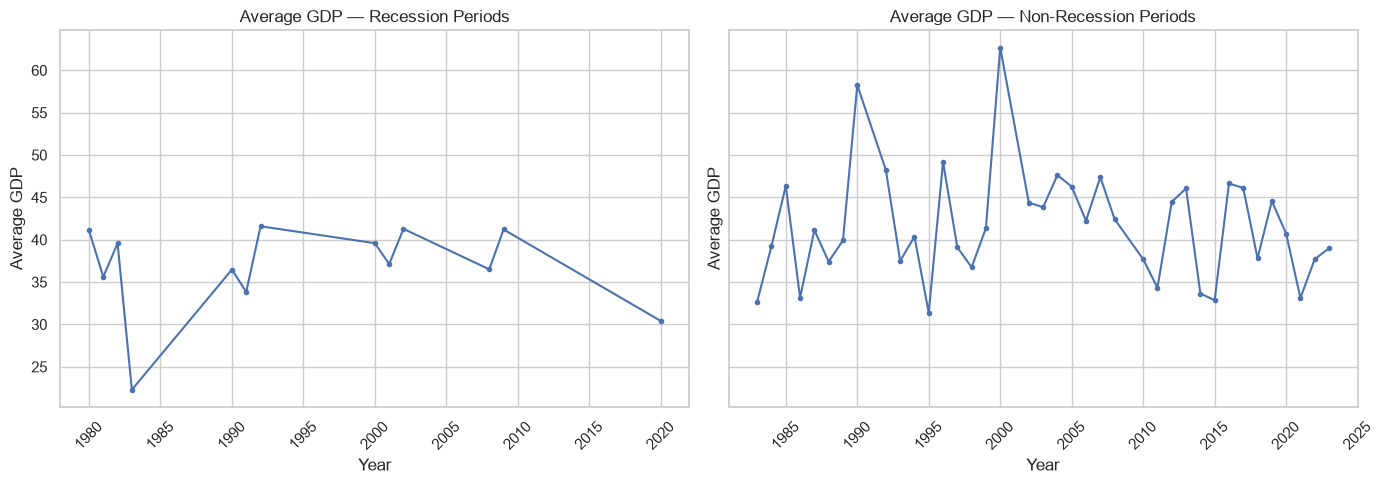

Interpretation (observed GDP means):
Recession
Non-recession    40.72
Recession        37.71


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14,5), sharey=True)
for ax, flag, title in zip(axes, [1,0], ['Recession Periods','Non-Recession Periods']):
    t = df.loc[df['Recession'] == flag].groupby('Year', as_index=False)['GDP'].mean()
    ax.plot(t['Year'], t['GDP'], marker='o', markersize=3)
    ax.set(title=f'Average GDP — {title}', xlabel='Year', ylabel='Average GDP')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (observed GDP means):')
print(df.groupby('Recession')['GDP'].mean().rename(index={0:'Non-recession', 1:'Recession'}).round(2).to_string())


## Task 1.5 — Seasonality bubble chart

Bubble area represents automobile sales while axes show month and seasonality weight.

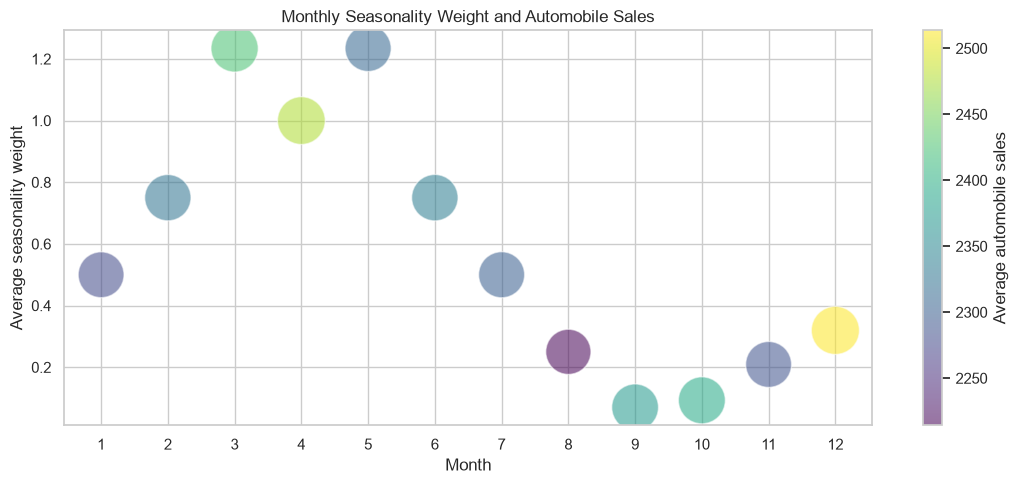

Interpretation (monthly grouped means): seasonality/sales correlation = 0.18


In [8]:
season = df.groupby('Month_Number',as_index=False).agg(Seasonality_Weight=('Seasonality_Weight','mean'),Automobile_Sales=('Automobile_Sales','mean'))
size = 1200 * season['Automobile_Sales'] / season['Automobile_Sales'].max()
fig, ax = plt.subplots(figsize=(11,5))
sc = ax.scatter(season['Month_Number'],season['Seasonality_Weight'],s=size,alpha=.55,c=season['Automobile_Sales'],cmap='viridis',edgecolor='white')
fig.colorbar(sc,ax=ax,label='Average automobile sales')
ax.set(title='Monthly Seasonality Weight and Automobile Sales',xlabel='Month',ylabel='Average seasonality weight',xticks=range(1,13))
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (monthly grouped means): seasonality/sales correlation =', round(season['Seasonality_Weight'].corr(season['Automobile_Sales']), 3))


## Task 1.6 — Price and automobile sales during recessions

The scatter plot shows association only; it does not establish causation.

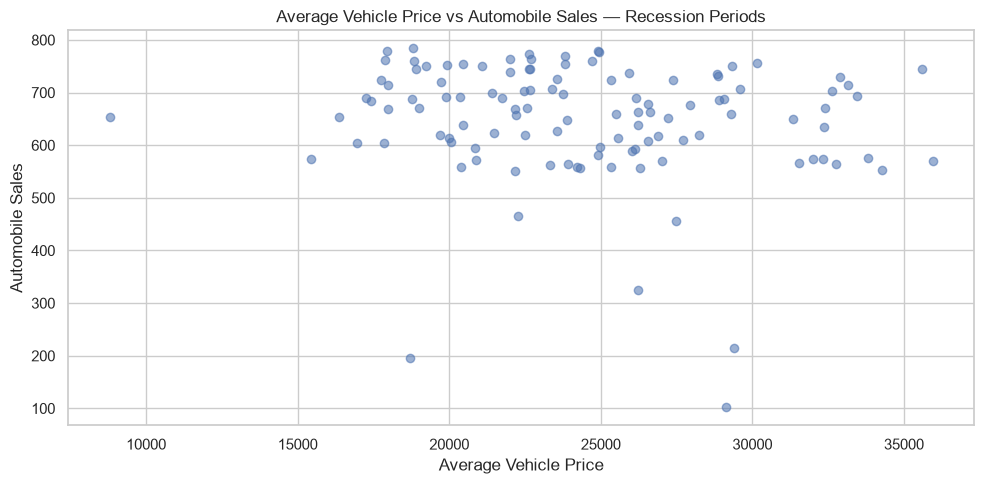

Interpretation (recession observations): price/sales Pearson correlation = -0.147


In [9]:
rec = df.loc[df['Recession'] == 1]
fig, ax = plt.subplots(figsize=(10,5))
ax.scatter(rec['Price'],rec['Automobile_Sales'],alpha=.55)
ax.set(title='Average Vehicle Price vs Automobile Sales — Recession Periods',xlabel='Average Vehicle Price',ylabel='Automobile Sales')
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (recession observations): price/sales Pearson correlation =', round(rec['Price'].corr(rec['Automobile_Sales']), 3))


## Task 1.7 — Share of advertising expenditure by economic period

Sum spending over recorded observations in each recession category.

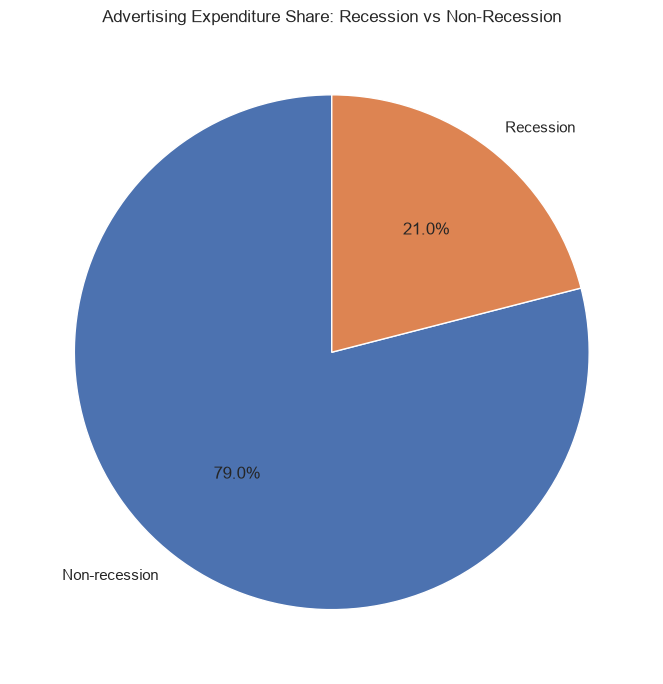

Interpretation (observed total advertising shares):
Recession
Non-recession    79.01
Recession        20.99


In [10]:
ad_period = df.groupby('Recession')['Advertising_Expenditure'].sum().reindex([0,1])
fig, ax = plt.subplots(figsize=(7,7))
ax.pie(ad_period,labels=['Non-recession','Recession'],autopct='%1.1f%%',startangle=90)
ax.set_title('Advertising Expenditure Share: Recession vs Non-Recession')
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (observed total advertising shares):')
print((100*ad_period/ad_period.sum()).round(2).rename(index={0:'Non-recession', 1:'Recession'}).to_string())


## Task 1.8 — Advertising allocation by vehicle type during recession

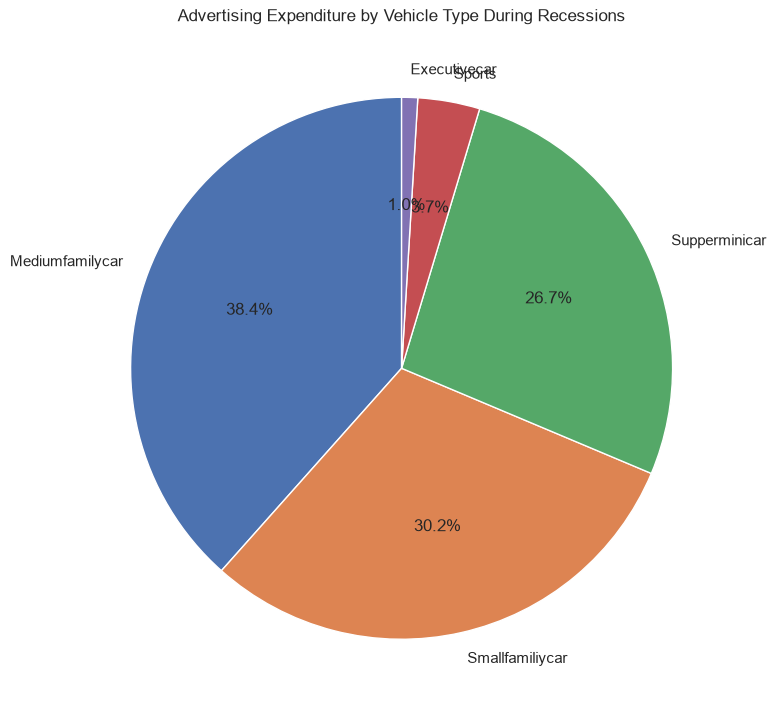

Interpretation (recession advertising allocation by type, %):
Vehicle_Type
Mediumfamilycar    38.43
Smallfamiliycar    30.23
Supperminicar      26.69
Sports              3.70
Executivecar        0.95


In [11]:
ad_vehicle = rec.groupby('Vehicle_Type')['Advertising_Expenditure'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8,8))
ax.pie(ad_vehicle,labels=ad_vehicle.index,autopct='%1.1f%%',startangle=90)
ax.set_title('Advertising Expenditure by Vehicle Type During Recessions')
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (recession advertising allocation by type, %):')
print((100*ad_vehicle/ad_vehicle.sum()).round(2).to_string())


## Task 1.9 — Unemployment rate and automobile sales by vehicle type

Aggregate observations with identical unemployment rates and vehicle types to show a line for each category.

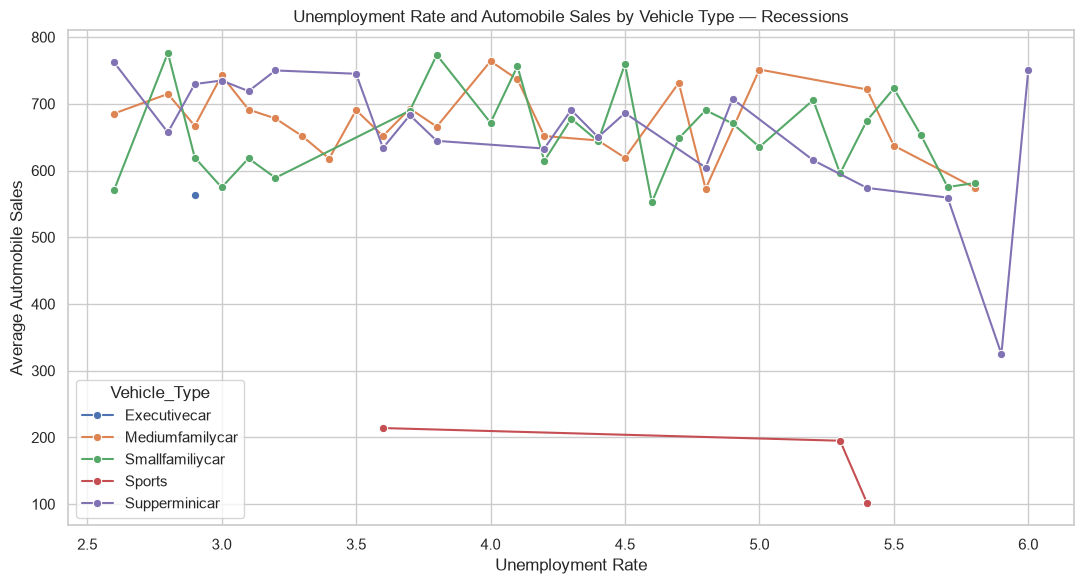

Interpretation (per-vehicle unemployment/sales correlations in recession data):
Vehicle_Type
Executivecar         NaN
Mediumfamilycar   -0.113
Smallfamiliycar   -0.014
Sports            -0.669
Supperminicar     -0.520


E:\automobile-sales-recession-analysis\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:3029: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
E:\automobile-sales-recession-analysis\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:2902: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
E:\automobile-sales-recession-analysis\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:2902: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


In [12]:
unemployment_sales = rec.groupby(['Vehicle_Type','unemployment_rate'],as_index=False)['Automobile_Sales'].mean()
fig, ax = plt.subplots(figsize=(11,6))
sns.lineplot(data=unemployment_sales,x='unemployment_rate',y='Automobile_Sales',hue='Vehicle_Type',marker='o',ax=ax)
ax.set(title='Unemployment Rate and Automobile Sales by Vehicle Type — Recessions',xlabel='Unemployment Rate',ylabel='Average Automobile Sales')
plt.tight_layout(); plt.show()
# Computed only when executed on the official IBM dataset.
print('Interpretation (per-vehicle unemployment/sales correlations in recession data):')
print(rec.groupby('Vehicle_Type')[['unemployment_rate', 'Automobile_Sales']].apply(lambda group: group['unemployment_rate'].corr(group['Automobile_Sales'])).round(3).to_string())


## Folium note

The nine specified tasks above do not include a geographic map. The IBM dataset must have legitimate coordinates or a documented region-to-coordinate mapping before a Folium map can be generated. Folium is imported as requested; no fictional geolocation is created.

## Interpretation and reproducibility

Only make numerical claims after actually executing this notebook on the official dataset. The project README and `docs/validation_report.md` explicitly describe the current validation status.

## Data-grounded findings

The following results are computed directly from the official IBM records when executed. They describe association, not causation.

In [13]:
comparison = df.groupby('Recession')['Automobile_Sales'].agg(['count','mean','median']).rename(index={0:'Non-recession', 1:'Recession'})
vehicle_comparison = df.groupby(['Vehicle_Type', 'Recession'])['Automobile_Sales'].mean().unstack()
print('Sales by period:')
print(comparison.to_string())
print('\nMean sales by vehicle type and period:')
print(vehicle_comparison.to_string())
print('\nMean difference, recession minus non-recession:', round(float(comparison.loc['Recession','mean'] - comparison.loc['Non-recession','mean']),2))

Sales by period:
               count         mean  median
Recession                                
Non-recession    415  2816.753590  2851.8
Recession        113   648.516814   669.4

Mean sales by vehicle type and period:
Recession                  0           1
Vehicle_Type                            
Executivecar     2686.436232  564.000000
Mediumfamilycar  2981.501935  674.847619
Smallfamiliycar  2752.658140  650.733333
Sports           2910.636264  170.333333
Supperminicar    2495.242222  659.270968

Mean difference, recession minus non-recession: -2168.24
